# 08 - Permeability

**Part A - Petrophys Curriculum**

Porosity tells you how much fluid a rock can *store*; **permeability** ($k$) tells
you how fast that fluid can *flow*. It is what separates a tight, uneconomic zone
from a productive one, and unlike porosity it is not directly measured by any wire-
line tool - we always *estimate* it, either from log-based correlations or by
calibrating to core.

This lesson covers the two workhorse log-based estimators (**Timur** and
**Coates-Denoo**), how to flag impermeable zones, and - most importantly - how to
**calibrate a poro-perm transform to core data** and honestly report its
uncertainty.

NMR logs give a third route: Timur-Coates and SDR permeability from the
bound- and free-fluid volumes and the T2 distribution. 30/6-5 has no NMR log, so
that route is covered in **lesson 14 (NMR petrophysics)** on a real CMR log.

## Learning goals

By the end of this lesson you will be able to:

- Explain why permeability is estimated, not measured, from logs.
- Run `timur` and `coates_denoo` from `petrophys.interpretation.permeability` and
  understand their inputs (porosity and irreducible water saturation $S_{wirr}$).
- Flag impermeable zones with `flag_impermeable`.
- Build a `CoreData` object and fit a poro-perm transform with
  `petrophys.interpretation.core_analysis.fit_poro_perm_transform`, reading off $A$, $B$ and $R^2$.
- Plot $\log_{10}(k)$ vs porosity with the fitted line, overlay predicted vs core
  permeability, and reason about the scatter.

## Why this matters

Permeability spans **many orders of magnitude** for small changes in porosity, so
it is always worked in $\log_{10}$ space. The classic log-based estimators tie $k$
to two things the logs *can* give us:

- **Porosity** $\phi$ - more, better-connected pore space flows more easily.
- **Irreducible water saturation** $S_{wirr}$ - the water clinging to grain
  surfaces that never flows. High $S_{wirr}$ means fine grains, large surface area,
  and *low* permeability.

**Timur (1968):**
$$ k = a\,\frac{\phi^{b}}{S_{wirr}^{\,c}} \qquad (a{=}0.136,\ b{=}4.4,\ c{=}2\ \text{on percent units}) $$

**Coates-Denoo:**
$$ k = 10000\,\phi^{4}\left(\frac{1-S_{wirr}}{S_{wirr}}\right)^{2} $$

Both are empirical and were tuned on particular rocks - which is exactly why we
end the lesson by calibrating to core.

### Prerequisites

Assumes the Part A lessons on porosity and water saturation (lesson 07). We
recompute porosity and an irreducible-water estimate inline so this lesson runs
standalone.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)

petrophys 3.0.0


## 1. Load the well and build porosity + $S_{wirr}$

We again use **30/6-5** and its Brent Group reservoir (2841-2958 m; labelled
`BAAT GP.` in the bundled tops), which carries laboratory core porosity (`PHIC`)
and core permeability (`KH_CORE`) - the ingredients we need for the calibration
section.

The log-based estimators need an **irreducible** water saturation, not the total
$S_w$. Where $S_{wirr}$ really comes from, in order of preference: capillary
pressure measurements (lesson 15), NMR bound-fluid volume (lesson 14), and
only then a log-based quick-look. The quick-look we use is the classic
**constant-BVW (Buckles)** construction: in rock that is *at* irreducible
saturation, the bulk volume of water $BVW = \phi \cdot S_w$ is roughly constant
for a rock type, so

$$ S_{wirr} = \frac{BVW_{irr}}{\phi} $$

which correctly gives poor rock a higher $S_{wirr}$ than good rock (finer grains,
more surface area, more bound water). A single constant $S_{wirr}$ (a low
percentile of clean-zone $S_w$) is the cruder alternative; it treats all rock
alike, over-predicting permeability in the poor rock. Either way there is a
**validity condition**: the calibration zone must genuinely be at irreducible
saturation. Here the upper Brent qualifies: above ~2900 m its clean-rock BVW is
low and nearly flat, while below 2900 m it is much higher - that rock is in
transition and must not anchor the pick. The next cell prints both, and checks
that the low percentile we use for $BVW_{irr}$ comes from the upper zone.

In [2]:
from petrophys.interpretation.clay_volume import vcl_from_gr
from petrophys.interpretation.porosity import density_porosity, neutron_porosity
from petrophys.interpretation.saturation import archie

well = read_las(petrophys.sample('30_6-5'))
TOP, BASE = 2841.0, 2958.0
res = well.depth_slice(TOP, BASE)

depth = res.depth
gr    = res.get('GR').data
rhob  = res.get('RHOB').data
nphi  = res.get('NPHI').data
rt    = res.get('RDEP').data

vcl  = vcl_from_gr(gr, np.nanpercentile(gr, 5), np.nanpercentile(gr, 95))
phie = np.clip((density_porosity(rhob) + neutron_porosity(nphi)) / 2.0, 0.0, 0.40)

# Operator evaluation constants (lessons 06, 07 and 09): Rw = 0.070 ohm.m at
# 230 F (the Brent reservoir temperature), a = 0.80, m = n = 2. The header's
# RW = 0.7 is not used (lesson 06 shows why).
RW = 0.070
sw = archie(rt, RW, phie, a=0.80, m=2.0, n=2.0)

# Swirr quick-look, Buckles construction: BVW_irr from the clean rock that is
# at irreducible saturation (low percentile of phi*Sw over clean Vcl<0.3
# samples), then Swirr = BVW_irr / phi per sample, so poor rock gets a higher
# Swirr than good rock. The cruder single-constant alternative (p10 of clean
# Sw) is printed for comparison; note it under-corrects the poor rock.
clean = np.isfinite(sw) & np.isfinite(phie) & (vcl < 0.3) & (phie > 0.05)
bvw = phie * sw
bvw_irr = float(np.nanpercentile(bvw[clean], 10))
swirr = np.clip(bvw_irr / np.where(phie > 0.01, phie, np.nan), 0.02, 1.0)

swirr_const = float(np.nanpercentile(sw[clean], 10))

# Validity check: is the clean rock above 2900 m at irreducible saturation?
upper = depth < 2900.0
print('Interval %.0f - %.0f m  (%d samples)' % (TOP, BASE, res.n_samples))
print('PHIE  mean : %.3f' % np.nanmean(phie))
print('Sw    mean : %.3f' % np.nanmean(sw))
print('clean-rock BVW above 2900 m : mean %.3f, std %.3f'
      % (np.nanmean(bvw[clean & upper]), np.nanstd(bvw[clean & upper])))
print('clean-rock BVW below 2900 m : mean %.3f, std %.3f'
      % (np.nanmean(bvw[clean & ~upper]), np.nanstd(bvw[clean & ~upper])))
low = clean & (bvw <= bvw_irr)
print('samples at or below BVW_irr that lie above 2900 m : %.0f %%'
      % (100.0 * np.mean(upper[low])))
print()
print('BVW_irr (p10 of phi*Sw over clean rock)        : %.4f' % bvw_irr)
print('Buckles Swirr at phi = 0.10 / 0.20 / 0.30      : %.2f / %.2f / %.2f'
      % (bvw_irr / 0.10, bvw_irr / 0.20, bvw_irr / 0.30))
print('(single-constant alternative, p10 of clean Sw  : %.3f)' % swirr_const)

Interval 2841 - 2958 m  (768 samples)
PHIE  mean : 0.211
Sw    mean : 0.579
clean-rock BVW above 2900 m : mean 0.059, std 0.025
clean-rock BVW below 2900 m : mean 0.178, std 0.033
samples at or below BVW_irr that lie above 2900 m : 100 %

BVW_irr (p10 of phi*Sw over clean rock)        : 0.0421
Buckles Swirr at phi = 0.10 / 0.20 / 0.30      : 0.42 / 0.21 / 0.14
(single-constant alternative, p10 of clean Sw  : 0.181)


## 2. Log-based permeability: Timur and Coates-Denoo

Both functions take **fractions** for porosity and $S_{wirr}$ and return
permeability in **millidarcies (mD)**. Timur converts to percent internally with
its conventional coefficient; you can override $a, b, c$ if you have a local tune.

In [3]:
from petrophys.interpretation.permeability import timur, coates_denoo

k_timur  = timur(phie, swirr)                 # defaults a=0.136, b=4.4, c=2.0
k_coates = coates_denoo(phie, swirr)

def stats(name, k):
    print('%-14s  mean=%8.1f  median=%8.1f  p10=%7.1f  p90=%8.1f mD'
          % (name, np.nanmean(k), np.nanmedian(k),
             np.nanpercentile(k, 10), np.nanpercentile(k, 90)))

stats('Timur', k_timur)
stats('Coates-Denoo', k_coates)


Timur           mean=   727.6  median=   214.0  p10=   27.9  p90=  1120.7 mD
Coates-Denoo    mean=  1001.1  median=   297.4  p10=   36.1  p90=  1571.2 mD


#### Comparing empirical models

Both estimates are in mD, but their distributions differ because Timur and
Coates-Denoo were calibrated on different rock populations. Core calibration
is needed to decide which response is appropriate for this well.


### Timur vs Coates-Denoo over depth

Plot the two estimates on a shared log scale alongside porosity and $S_{wirr}$.
Where the curves diverge you are most sensitive to which correlation you trust.

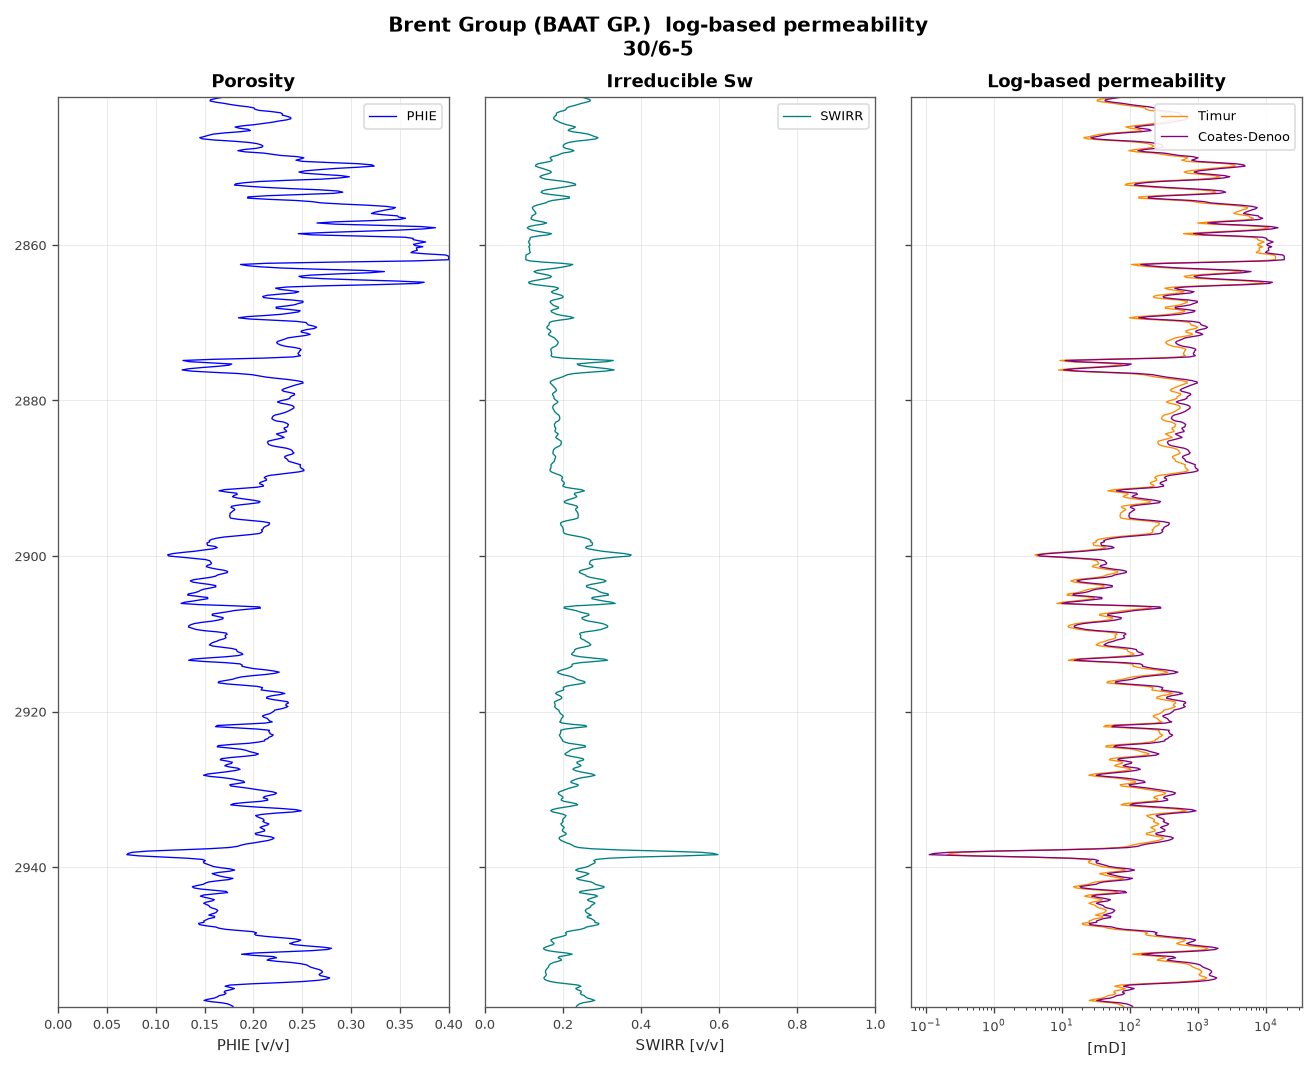

In [4]:
# Depth overlay via the library LogPlot. Attach PHIE, Swirr and both
# log-permeability estimates to the sliced reservoir well.
from petrophys.visualization import LogPlot

res.add_curve('PHIE',    phie,     'v/v', 'Effective porosity')
res.add_curve('SWIRR',   swirr,    'v/v', 'Irreducible Sw')
res.add_curve('K_TIMUR', k_timur,  'mD',  'Timur permeability')
res.add_curve('K_COATES', k_coates, 'mD', 'Coates-Denoo permeability')

lp = LogPlot(res, figsize=(11, 9))
lp.create_figure(n_tracks=3)

lp.add_curve(0, 'PHIE', color='blue', linewidth=0.8, xlim=(0, 0.4))
lp.axes[0].set_title('Porosity')

lp.add_curve(1, 'SWIRR', color='teal', linewidth=0.8, xlim=(0, 1))
lp.axes[1].set_title('Irreducible Sw')

lp.add_curve(2, 'K_TIMUR',  color='darkorange', linewidth=0.8, log_scale=True,
             label='Timur')
lp.add_curve(2, 'K_COATES', color='purple',     linewidth=0.8, log_scale=True,
             label='Coates-Denoo')
lp.axes[2].set_title('Log-based permeability')

lp.add_title('Brent Group (BAAT GP.)  log-based permeability')
lp.set_depth_range(TOP, BASE)
lp.show()

## 3. Flagging impermeable zones

Not every zone flows. `flag_impermeable(phi_s, phi_d, phi_n)` uses porosity-log
disagreement as a tell-tale: it flags a sample impermeable when the **sonic**
porosity greatly exceeds the **density** porosity ($\phi_S > 1.5\,\phi_D$ - the
signature of clay or undercompaction inflating the sonic slowness; note that a
vuggy rock shows the *opposite* pattern, because the sonic under-reads secondary
porosity), **or** when **neutron** porosity runs well above density
($\phi_N > \phi_D + 0.15$, the classic shale/clay-bound-water signature).

We build the three porosities from the logs: density from RHOB, neutron from NPHI,
and sonic from the compressional slowness `DTC`.

In [5]:
from petrophys.interpretation.porosity import sonic_porosity
from petrophys.interpretation.permeability import flag_impermeable

dtc = res.get('DTC').data

phi_d = density_porosity(rhob, rhob_matrix=2.65, rhob_fluid=1.0)
phi_n = neutron_porosity(nphi)
phi_s = sonic_porosity(dtc, matrix='sandstone')

impermeable = flag_impermeable(phi_s, phi_d, phi_n)

n_flag = int(np.nansum(impermeable))
print('Samples flagged impermeable : %d of %d (%.1f%%)'
      % (n_flag, impermeable.size, 100.0 * n_flag / impermeable.size))


Samples flagged impermeable : 364 of 768 (47.4%)


#### Interpreting the impermeable flag

Flagged samples commonly represent clay-rich or poorly connected streaks. The
flag can be used with the other reservoir criteria when defining net reservoir
and net pay in lesson 09.


## 4. Core calibration - the whole point

Log-based estimators are generic. The gold standard is to **fit the poro-perm
relationship to the field's own core plugs**. `fit_poro_perm_transform(core)` takes
a `CoreData` object and least-squares fits

$$ \log_{10}(k) = A\,\phi + B $$

returning a `PoroPermTransform` with `A`, `B`, `r_squared`, `n_points`, `rmse` and a
`.predict(porosity)` method.

30/6-5 stores its core measurements as curves (`PHIC`, `KH_CORE`). The helper
`core_data_from_well` reads those straight off the well into a `CoreData`.

In [6]:
import warnings
from petrophys.interpretation.core_analysis import CoreData, fit_poro_perm_transform
from petrophys.interpretation.core_analysis.calibration import core_data_from_well

# core_data_from_well returns core saturations as fractions. This well stores
# SWC/SOC as percent labelled 'frac', so it converts them and says so.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    core = core_data_from_well(well)  # reads PHIC, KH_CORE, etc. across the whole well
for note in caught:
    print("note:", note.message)
print('Core plugs                 :', len(core.depth))
print('Has porosity / permeability:', core.porosity is not None,
      '/', core.permeability is not None)
print('Core porosity curve used   :', core.metadata.get('core_porosity_curve'))
print('Core perm curve used       :', core.metadata.get('core_permeability_curve'))

transform = fit_poro_perm_transform(core)
print()
print('Fitted transform (method=%s):' % transform.method)
print('  log10(k) = %.2f * PHI + (%.2f)' % (transform.A, transform.B))
print('  R^2   = %.3f' % transform.r_squared)
print('  RMSE  = %.3f  (log10 mD units)' % transform.rmse)
print('  n     = %d core points' % transform.n_points)

note: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
note: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
Core plugs                 : 201
Has porosity / permeability: True / True
Core porosity curve used   : PHIC
Core perm curve used       : KH_CORE

Fitted transform (method=core_fit):
  log10(k) = 21.72 * PHI + (-2.54)
  R^2   = 0.777
  RMSE  = 0.742  (log10 mD units)
  n     = 198 core points


### The core crossplot with the fitted line

The canonical QC plot: core $\log_{10}(k)$ on the y-axis against core porosity on
the x-axis, with the fitted transform overlaid. A tight cloud around the line means
a single porosity-permeability trend describes the rock; a fat cloud means other
controls (grain size, cementation, facies) matter and a single transform carries
real uncertainty.

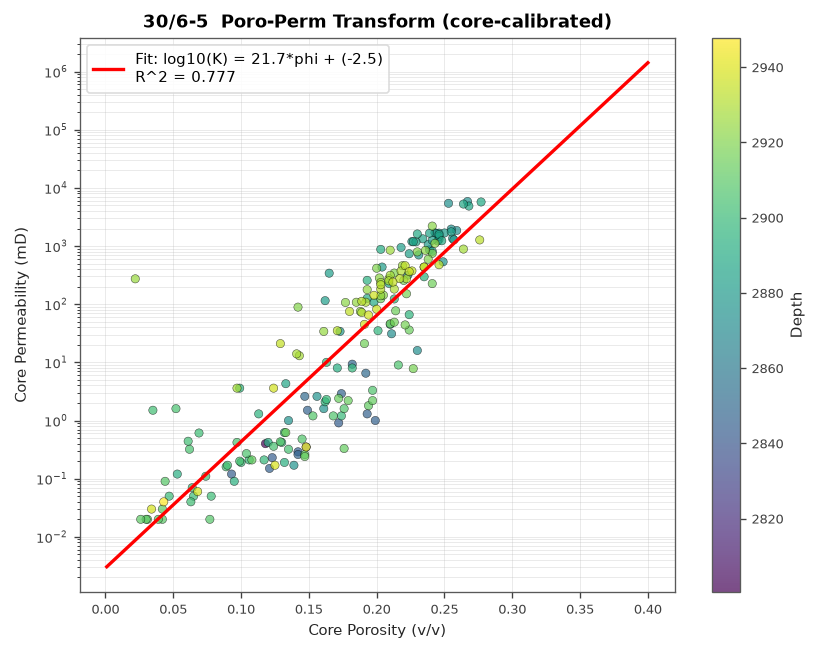

In [7]:
# Core poro-perm crossplot with the fitted transform overlaid, via the library
# core plotter petrophys.visualization.core.plot_poro_perm (takes CoreData + PoroPermTransform).
from petrophys.visualization.core import plot_poro_perm

fig, ax = plot_poro_perm(core, transform=transform, figsize=(8, 6),
                         title='30/6-5  Poro-Perm Transform (core-calibrated)')
plt.show()

### Predicted vs core permeability (unity plot)

Apply the transform back to the core porosities and cross-plot predicted against
measured permeability. Points on the 1:1 line are perfectly predicted; the vertical
scatter around it is the transform's intrinsic error. Because $k$ is log-normal,
we judge this in $\log_{10}$ space. The public calibration API does the whole QC:
`apply_poro_perm_transform` writes the predicted-permeability curve onto the well
and `calibrate_permeability` compares it against the core values in $\log_{10}$
space.

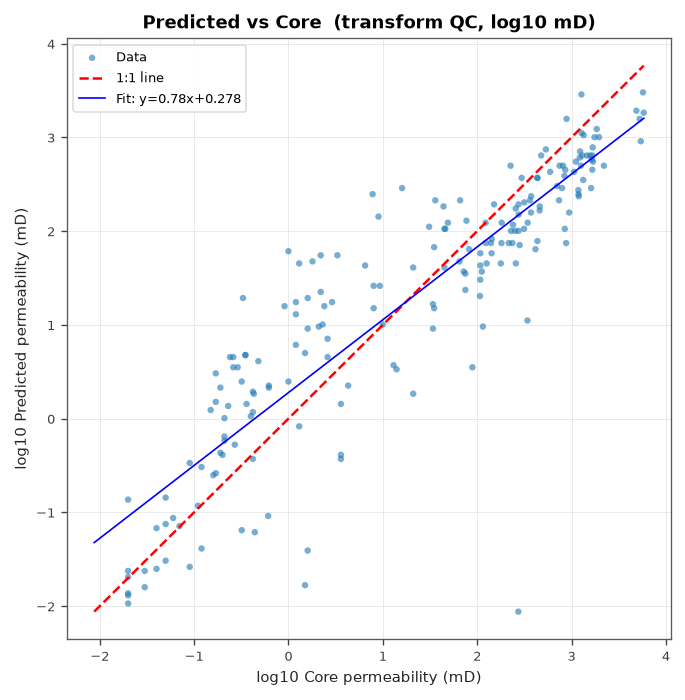

log10 RMSE : 0.742  ->  typical error is a factor of ~5.5x


In [8]:
# Predicted-vs-core QC as a library calibration crossplot (1:1 line + fit),
# using the public API: apply the fitted transform to the well's PHIC curve to
# make a predicted-permeability curve, then compare it against the core
# permeability with calibrate_permeability (stats in log10 space) and render
# the result with plot_calibration.
from petrophys.visualization.core import plot_calibration
from petrophys.interpretation.core_analysis import (calibrate_permeability,
                            apply_poro_perm_transform)

apply_poro_perm_transform(well, transform, porosity_curve='PHIC',
                          output_curve='K_PRED')
cal = calibrate_permeability(well, core, log_curve='K_PRED', log_scale=True)

fig, ax = plot_calibration(cal, figsize=(6.5, 6.5),
                           title='Predicted vs Core  (transform QC, log10 mD)')
ax.set_xlabel('log10 Core permeability (mD)')
ax.set_ylabel('log10 Predicted permeability (mD)')
plt.show()

# Report the multiplicative error band (10^RMSE) implied by the log10 RMSE.
factor = 10 ** cal.rmse
print('log10 RMSE : %.3f  ->  typical error is a factor of ~%.1fx'
      % (cal.rmse, factor))


#### Calibration quality

The multiplicative error is wider than the factor-of-two to factor-of-three
range expected from a strong clastic calibration. Mixing several facies within
one transform is a likely source of the residual spread.


## 5. A second core dataset - Costa (HW-3)

To show the workflow is general, we build a `CoreData` by hand from the Costa
carbonate well **HW-3**, which carries core-corrected porosity/permeability
curves (`PHIE_CC`, `PERM_CC` - a stand-in for a plug table here). Like every
Costa file, it covers only the Kharaib-2 reservoir interval. Constructing
`CoreData` directly is the pattern you use when your core arrives as a table
rather than as LAS curves.

In [9]:
hw3 = read_las(petrophys.sample('HW-3'))

core_hw3 = CoreData(
    depth       = hw3.depth,
    porosity    = hw3.get('PHIE_CC').data,
    permeability= hw3.get('PERM_CC').data,
)
transform_hw3 = fit_poro_perm_transform(core_hw3)

print('HW-3 (carbonate) transform :')
print('  log10(k) = %.2f * PHI + (%.2f)' % (transform_hw3.A, transform_hw3.B))
print('  R^2 = %.3f over %d samples' % (transform_hw3.r_squared, transform_hw3.n_points))
print()
print('Compare the two fields:')
print('  30/6-5 (clastic)  : log10(k)=%.1f*PHI%+.1f,  R2=%.2f'
      % (transform.A, transform.B, transform.r_squared))
print('  HW-3   (carbonate): log10(k)=%.1f*PHI%+.1f,  R2=%.2f'
      % (transform_hw3.A, transform_hw3.B, transform_hw3.r_squared))

HW-3 (carbonate) transform :
  log10(k) = 5.74 * PHI + (-0.50)
  R^2 = 0.360 over 324 samples

Compare the two fields:
  30/6-5 (clastic)  : log10(k)=21.7*PHI-2.5,  R2=0.78
  HW-3   (carbonate): log10(k)=5.7*PHI-0.5,  R2=0.36


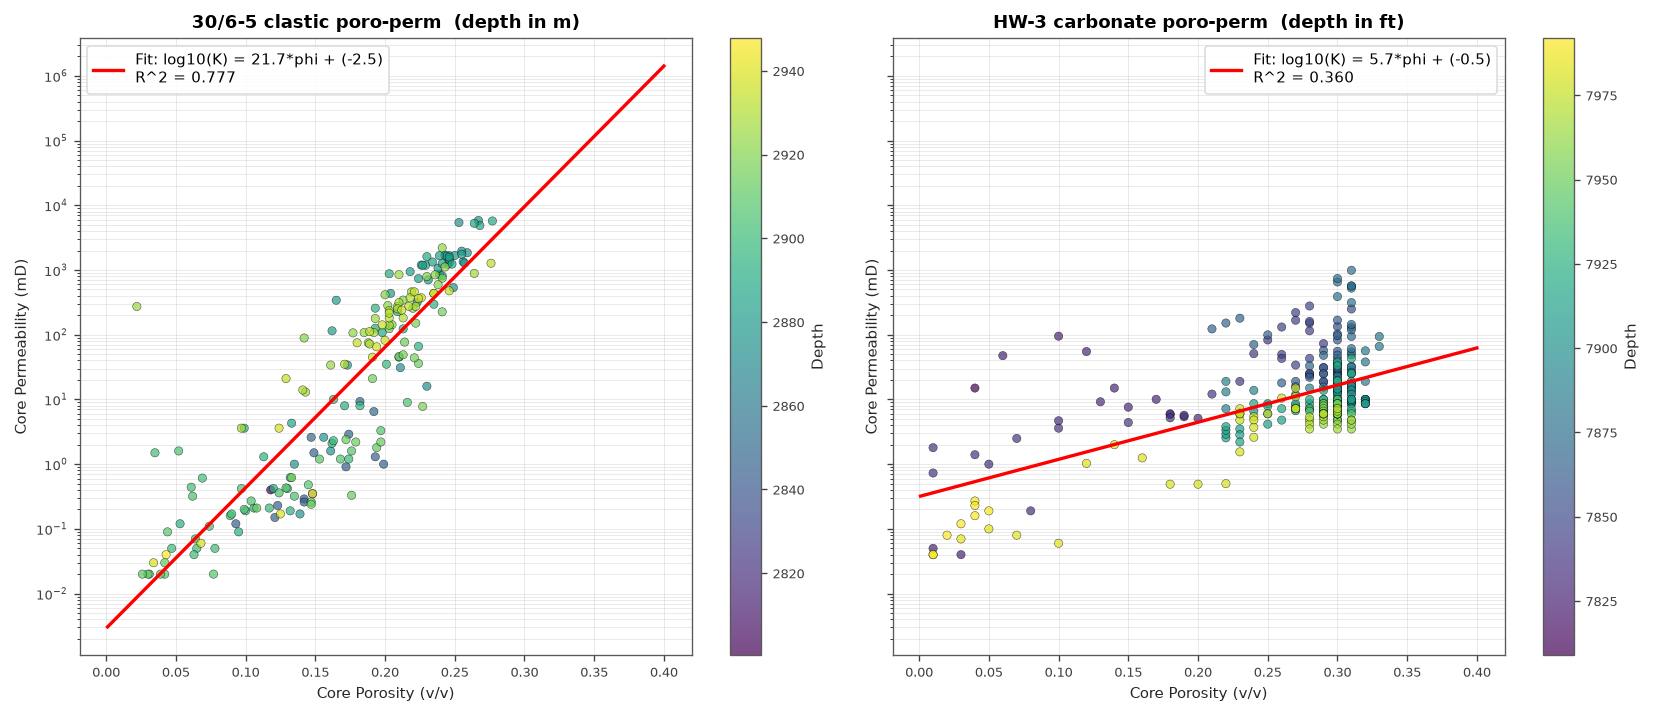

In [10]:
# Show the two core datasets side by side, each with its fitted transform and
# its own depth colorbar (30/6-5 in metres, HW-3 in feet), so each cloud stays
# attributable to its field (one plot_poro_perm call per axes).
from petrophys.visualization.core import plot_poro_perm

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
plot_poro_perm(core,     transform=transform,     ax=ax1,
               title='30/6-5 clastic poro-perm  (depth in m)')
plot_poro_perm(core_hw3, transform=transform_hw3, ax=ax2,
               title='HW-3 carbonate poro-perm  (depth in ft)')
plt.tight_layout()
plt.show()

### Interpreting the two trends

The **clastic** 30/6-5 cloud is tight (high $R^2$): a single porosity value
predicts permeability well, because in a fairly uniform sand porosity and
throat size scale together. The **carbonate** HW-3 cloud is looser (lower $R^2$):
carbonate permeability is controlled by pore *type* (intergranular vs vuggy vs
fractured) as much as by bulk porosity, so a single $\phi$-$k$ line leaves more
residual scatter. This is the same clastic-vs-carbonate contrast we saw for
saturation in lesson 07 - the carbonate demands more than a bulk-property law.

## Uncertainty - how much should you trust a permeability estimate?

Permeability is the least certain number in the evaluation. Sources of error:

- **The correlation is empirical.** Timur/Coates were tuned on specific rocks; off
  that rock type they can be off by an order of magnitude.
- **$S_{wirr}$ is itself estimated.** Since Timur has $S_{wirr}^{-2}$, a 20% error
  in $S_{wirr}$ moves $k$ by ~40%.
- **Core-to-log scale mismatch.** A core plug is centimetres; a log sample averages
  decimetres. Vertical permeability, fractures and lamination are averaged
  differently.
- **The transform's own RMSE.** We reported it as a multiplicative factor - a "x2
  to x3" band is common and honest for a good clastic fit; carbonates are worse.

**Best practice:** report permeability as a *range* (e.g. P10/P50/P90 from the
transform residuals), always calibrate to core when core exists, and treat any
single deterministic $k$ curve with healthy suspicion.

## Pitfalls & parameter choices

- **Fractions in, mD out.** Both estimators expect $\phi$ and $S_{wirr}$ as
  fractions (0-1). Passing percent silently gives nonsense.
- **Use $S_{wirr}$, not $S_w$.** Feeding the full water saturation (which includes
  moveable water in transition zones) underestimates permeability.
- **Always work $k$ in $\log_{10}$.** Averaging permeability linearly is dominated
  by a few high values; the geometric mean (mean of $\log_{10}$) is the sensible
  central estimate.
- **A high transform $R^2$ is necessary but not sufficient** - check the unity plot
  for bias (points systematically above/below the 1:1 line).

## Recap

- Permeability is always **estimated**, never logged; work it in $\log_{10}$ space.
- **Timur** ($k = a\phi^b / S_{wirr}^c$) and **Coates-Denoo**
  ($k = 10^4 \phi^4 ((1-S_{wirr})/S_{wirr})^2$) are the standard log-based
  estimators and need porosity and $S_{wirr}$.
- **`flag_impermeable`** uses porosity-log disagreement to mark non-flowing streaks.
- **`fit_poro_perm_transform(core)`** fits $\log_{10}(k)=A\phi+B$ to core plugs;
  read off $A$, $B$, $R^2$, RMSE and use `.predict()`.
- Clastic poro-perm trends are tight; carbonate trends are loose - pore type, not
  just porosity, controls carbonate flow.
- Report permeability with an **uncertainty band**, not a single deterministic
  value.
- Where an NMR log exists, NMR permeability is a further route (lesson 14).

## Try it yourself

> **Exercise 1.** Re-fit the 30/6-5 transform after excluding the highest-perm
> plug (the 5826 mD outlier). How much do $A$, $B$ and $R^2$ move? What does that
> tell you about the transform's sensitivity to a single point?
>
> **Exercise 2.** Apply `transform.predict(phie)` to the *log* porosity over the
> reservoir and overlay it on the Timur and Coates-Denoo curves from section 2.
> Which log-based estimator is closer to the core-calibrated answer?
>
> **Exercise 3.** Recompute Timur with $S_{wirr}$ set 20% higher everywhere. By
> what factor does mean permeability change? Relate it to the $S_{wirr}^{-2}$ term.

## What's next

Continue with **09 - Reservoir Quality and Net Pay**, where permeability feeds into
flow-zone indicators (RQI/FZI), bulk-volume water, the three-stage net-pay flag,
and volumetrics (HCPV / OOIP / OGIP).